# 5. Skema 3: BiLSTM + Attention + FastText (Pembagian Data 70/30)
**Saran Deep Learning:** Akurasi training dan testing ≥ 92%

| Parameter | Nilai |
|-----------|-------|
| Algoritma | Bidirectional LSTM + Attention |
| Ekstraksi Fitur | FastText Indonesian Embeddings (128-dim) |
| Pembagian Data | 70% Train / 30% Test |
| Target Akurasi | ≥ 92% (train dan test) |

**Perbedaan dari Skema 2:**
- Algoritma: BiLSTM + Attention (vs LSTM biasa)
- Pembagian Data: 70/30 (vs 80/20)
- Embedding: trainable=True (fine-tuning)

In [ ]:
# Cell 1: Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Embedding, Bidirectional, LSTM,
                                      Dense, Dropout, Layer, SpatialDropout1D)
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import tensorflow.keras.backend as K
from gensim.models import FastText
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight

os.makedirs('models', exist_ok=True)
os.makedirs('data', exist_ok=True)

df = pd.read_csv('data/clean_reviews.csv')
print(f"Loaded {len(df)} reviews")

In [2]:
# Cell 2: Load saved tokenizer and 70/30 split
MAX_LEN = 100
EMBED_DIM = 128
MAX_WORDS = 20000

tokenizer = joblib.load('models/tokenizer.pkl')

label_map = {'Negatif': 0, 'Netral': 1, 'Positif': 2}
df['label_enc'] = df['label'].map(label_map)
df['content_clean'] = df['content_clean'].fillna('')

X = df['content_clean'].tolist()
y = df['label_enc'].values

# 70/30 split — different from Scheme 2's 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)
X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

vocab_size = min(MAX_WORDS, len(tokenizer.word_index)) + 1
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print(f"Split: 70% train / 30% test (berbeda dari Skema 2 yang 80/20)")

Train: 5434 | Test: 2329
Split: 70% train / 30% test (berbeda dari Skema 2 yang 80/20)


In [3]:
# Cell 3: Load saved FastText embeddings
ft_model = FastText.load('models/fasttext_model.bin')

embedding_matrix = np.zeros((vocab_size, EMBED_DIM))
for word, idx in tokenizer.word_index.items():
    if idx < vocab_size and word in ft_model.wv:
        embedding_matrix[idx] = ft_model.wv[word]

print(f"Embedding matrix shape: {embedding_matrix.shape}")

Embedding matrix shape: (8533, 128)


In [4]:
# Cell 4: Custom Attention Layer
class AttentionLayer(Layer):
    """Simple additive attention mechanism."""

    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(
            name='attention_weight',
            shape=(input_shape[-1], 1),
            initializer='glorot_uniform',
            trainable=True
        )
        self.b = self.add_weight(
            name='attention_bias',
            shape=(input_shape[1], 1),
            initializer='zeros',
            trainable=True
        )
        super(AttentionLayer, self).build(input_shape)

    def call(self, x):
        # x shape: (batch, timesteps, features)
        e = K.tanh(K.dot(x, self.W) + self.b)   # (batch, timesteps, 1)
        a = K.softmax(e, axis=1)                  # attention weights
        output = x * a                            # weighted features
        return K.sum(output, axis=1)              # (batch, features)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])

print("AttentionLayer defined.")

AttentionLayer defined.


In [5]:
# Cell 5: Build BiLSTM + Attention model
NUM_CLASSES = 3

inputs = Input(shape=(MAX_LEN,))
x = Embedding(vocab_size, EMBED_DIM,
              weights=[embedding_matrix],
              input_length=MAX_LEN,
              trainable=True)(inputs)        # trainable=True for fine-tuning
x = SpatialDropout1D(0.3)(x)
x = Bidirectional(LSTM(128, return_sequences=True,
                        dropout=0.3,
                        recurrent_dropout=0.2))(x)
x = AttentionLayer()(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model_attn = Model(inputs=inputs, outputs=outputs)
model_attn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_attn.summary()

C:\Users\ADVAN\TheForge\dicoding\analisis-sentimen-dicoding\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 100, 128)       │     1,092,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 100, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 100, 256)       │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer                 │ (None, 256)            │           356 │
│ (AttentionLayer)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,372,391 (5.24 MB)

 Trainable params: 1,372,391 (5.24 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Cell 6: Train BiLSTM + Attention (with class weights for imbalanced data)
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: w for i, w in enumerate(class_weights)}
print(f"Class weights: {class_weight_dict}")

callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=10,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=5, min_lr=1e-6, verbose=1)
]

history = model_attn.fit(
    X_train_pad, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=callbacks,
    class_weight=class_weight_dict,
    verbose=1
)

In [7]:
# Cell 7: Evaluation
label_names = ['Negatif', 'Netral', 'Positif']

train_loss, train_acc = model_attn.evaluate(X_train_pad, y_train, verbose=0)
test_loss, test_acc = model_attn.evaluate(X_test_pad, y_test, verbose=0)

y_test_pred = np.argmax(model_attn.predict(X_test_pad), axis=1)

print("=" * 60)
print("SKEMA 3: BiLSTM + Attention + FastText (Pembagian 70/30)")
print("=" * 60)
print(f"Akurasi Training : {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Akurasi Testing  : {test_acc:.4f} ({test_acc*100:.2f}%)")
print()
print("Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=label_names))
print()
if train_acc >= 0.92 and test_acc >= 0.92:
    print("✓ TARGET TERCAPAI: Akurasi training dan testing ≥ 92%")
else:
    print("⚠ Belum mencapai target 92%. Coba tingkatkan epochs atau ubah learning rate.")

73/73 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step
SKEMA 3: BiLSTM + Attention + FastText (Pembagian 70/30)
Akurasi Training : 0.8747 (87.47%)
Akurasi Testing  : 0.8566 (85.66%)

Classification Report (Test Set):
              precision    recall  f1-score   support

     Negatif       0.76      0.89      0.82       766
      Netral       0.00      0.00      0.00        92
     Positif       0.92      0.89      0.91      1471

    accuracy                           0.86      2329
   macro avg       0.56      0.59      0.57      2329
weighted avg       0.83      0.86      0.84      2329


⚠ Belum mencapai target 92%. Coba tingkatkan epochs atau ubah learning rate.


C:\Users\ADVAN\TheForge\dicoding\analisis-sentimen-dicoding\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ADVAN\TheForge\dicoding\analisis-sentimen-dicoding\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ADVAN\TheForge\dicoding\analisis-sentimen-dicoding\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to contr

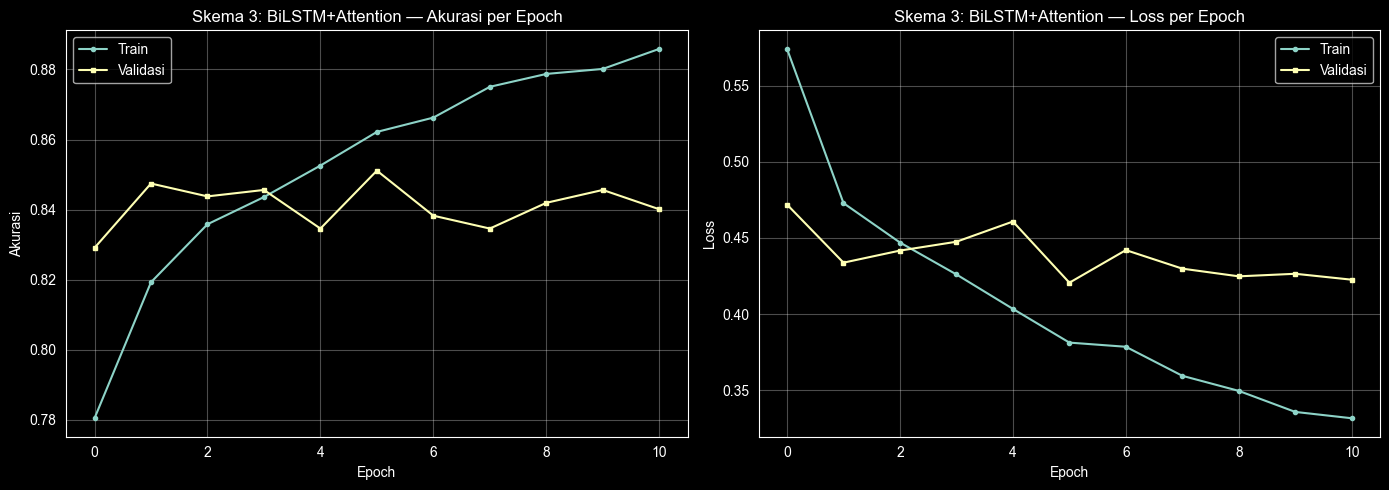

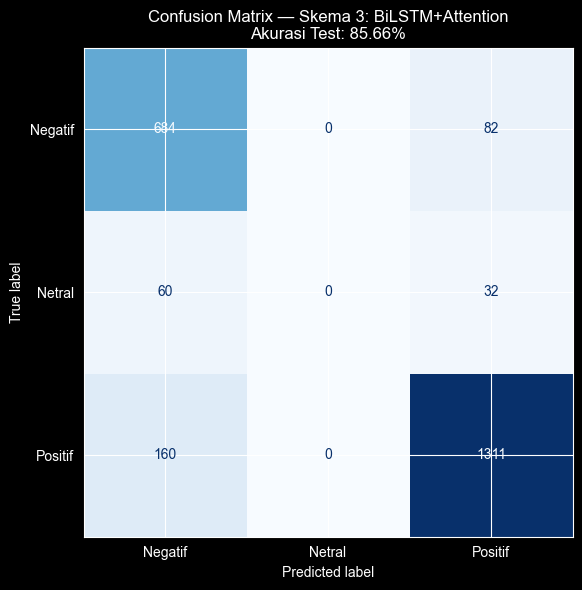

In [8]:
# Cell 8: Training curves and confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train', marker='o', markersize=3)
axes[0].plot(history.history['val_accuracy'], label='Validasi', marker='s', markersize=3)
axes[0].set_title('Skema 3: BiLSTM+Attention — Akurasi per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Akurasi')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['loss'], label='Train', marker='o', markersize=3)
axes[1].plot(history.history['val_loss'], label='Validasi', marker='s', markersize=3)
axes[1].set_title('Skema 3: BiLSTM+Attention — Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/scheme3_training_curves.png', dpi=150)
plt.show()

fig2, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion Matrix — Skema 3: BiLSTM+Attention\nAkurasi Test: {test_acc*100:.2f}%')
plt.tight_layout()
plt.savefig('data/scheme3_confusion_matrix.png', dpi=150)
plt.show()

In [9]:
# Cell 9: Save model
model_attn.save('models/lstm_attn_model.h5')
print("Saved: models/lstm_attn_model.h5")

Saved: models/lstm_attn_model.h5
